### **Introduction to Control with Learning**
# Introduction to OpenAI Gym and FrozenLake



This notebook guides you through:
1. Exploring the FrozenLake environment in OpenAI Gym
2. Understanding the transition dynamics (env.P)
3. Implementing Policy Evaluation
4. Implementing Policy Improvement and Policy Iteration

---

We will use the **FrozenLake-v1** environment — a classic example of a discrete, stochastic control problem on a 4×4 grid. The agent's goal is to reach the goal tile without falling into holes, navigating slippery ice.

Official environment documentation:  
👉 [https://www.gymlibrary.dev/environments/toy_text/frozen_lake/](https://www.gymlibrary.dev/environments/toy_text/frozen_lake/)

---

## 1. Setup and Environment Initialization

In [36]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np

if not hasattr(np, 'bool8'):
    np.bool8 = np.bool_

# require libraries
import gym
import time
import pygame
from IPython import display
import matplotlib.pyplot as plt


## 2. Environment Exploration
Let's inspect the state and action spaces, and the transition model `env.P`.


In [37]:
env = gym.make('FrozenLake-v1', desc=None, map_name='4x4', is_slippery=False, new_step_api=False)
num_states = env.observation_space.n
num_actions = env.action_space.n
print("Number of states:", num_states)
print("Number of actions:", num_actions)
# Show transitions for state 0, action 1
for prob, next_state, reward, done in env.P[0][1]:
    print(f"Transition probability: {prob}, Next state: {next_state}, Reward: {reward}, Done: {done}")

Number of states: 16
Number of actions: 4
Transition probability: 1.0, Next state: 4, Reward: 0.0, Done: False


The new episode will start in state 0


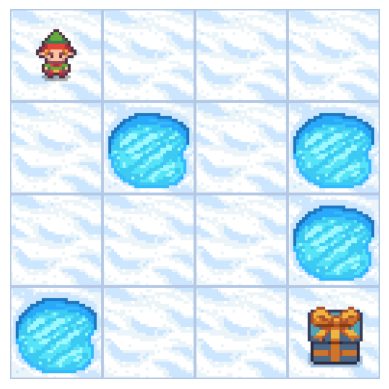

In [38]:
state = env.reset()
plt.axis('off')
plt.imshow(env.render(mode='rgb_array'));
print(f'The new episode will start in state {state}')

After moving down 1 row, the agent is in state: 4
After moving down 1 row, we got a reward of: 0.0
After moving down 1 row, the task is not finished


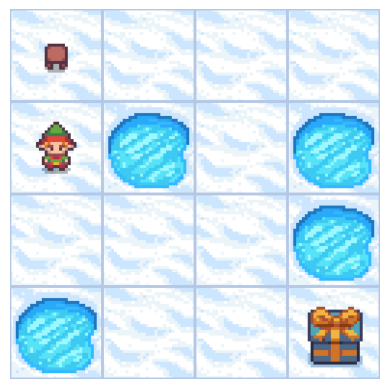

In [39]:
# 0: Left, 1: Down, 2: Right, 3: Up
action = 1
next_state, reward, done, info = env.step(action)
print(f"After moving down 1 row, the agent is in state: {next_state}")
print(f"After moving down 1 row, we got a reward of: {reward}")
print("After moving down 1 row, the task is", "" if done else "not", "finished")
plt.axis('off')
plt.imshow(env.render(mode='rgb_array'));

You achievd 0.0 reward in 7 moves in 1 episode:[[0, 0.0, False], [0, 0.0, False], [1, 0.0, False], [2, 0.0, False], [2, 0.0, False], [6, 0.0, False], [5, 0.0, True]]


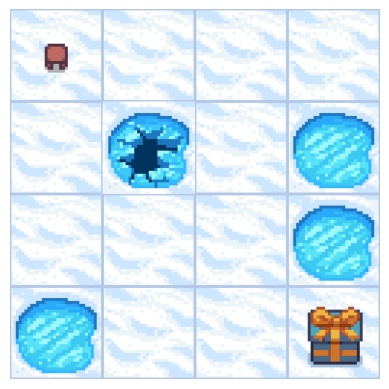

In [40]:
state = env.reset()
done = False
episode = []
t = 0

while not done:
    time.sleep(0.5)
    action = env.action_space.sample()
    next_state, reward, done, _ = env.step(action)
    episode.append([next_state, reward, done])
    state = next_state
    t += 1

    plt.axis('off')
    plt.imshow(env.render(mode='rgb_array'))
    display.display(plt.gcf())
    display.clear_output(wait=True)

env.close()

print(f'You achievd {reward} reward in {t} moves in 1 episode:{episode}')

## 3. Policy Evaluation


In [41]:
random_policy = np.ones((num_states, num_actions))/num_actions
print(f'Random Policy :\n{random_policy}')

Random Policy :
[[0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]]


When policy $\pi(a\mid s)$ is fixed, its value function satisfies the Bellman expectation equation:

$$
V^\pi(s) = \sum_a \pi(a\mid s) \sum_{s'} P(s'\mid s,a) \bigl[R(s,a,s') + \gamma V^\pi(s')\bigr].
$$

### Your task:

- Implement an iterative algorithm to compute $V^\pi$ for all states.
- Initialize $V(s) = 0$ for all states.
- Update $V(s)$ repeatedly using the above equation until the values converge.
- Stop when the maximum change in value across all states is less than a threshold (e.g., $\theta = 10^{-6}$).


In [42]:
gamma = 0.99
theta = 1e-6


# def policy_evaluation(policy):
#     ##########################################
#     ##########################################
#     ############## To Implement ##############
#     ##########################################
#     ##########################################
#     V = None

#     return V

def policy_evaluation(policy):
  V = np.zeros(num_states)
  while True:
    delta = 0.0
    for s in range(num_states):
      v_old = V[s]
      v_new = 0.0

      #sum over actions under pi
      for a, action_prob in enumerate(policy[s]):
        for prob, next_state, reward, done in env.P[s][a]:
          v_new += action_prob * prob * (reward + gamma * V[next_state])

      V[s] = v_new
      delta = max(delta, np.abs(v_new - v_old))

    if delta < theta:
      break
  return V


V = policy_evaluation(random_policy)
print(f'Policy Evaluation: \n {V.reshape(4, 4)}')


Policy Evaluation: 
 [[0.01235356 0.01042298 0.01933735 0.00947697]
 [0.01478582 0.         0.03889412 0.        ]
 [0.0326019  0.08433739 0.13781067 0.        ]
 [0.         0.17034467 0.43357932 0.        ]]


## 4. Policy Improvement
Given a value function \(V(s)\), the greedy policy satisfies:

$$
\pi_{new}(s) = \arg\max_a \sum_{s'} P(s'\mid s,a) \bigl[R(s,a,s') + \gamma V(s')\bigr].
$$


### Your task:
- For each state, compute the Q-value for each possible action using the current value function \(V(s)\).
- Select the action that maximizes the Q-value for that state.
- Build a deterministic policy that always chooses this greedy action.


In [43]:
# def policy_imporovement(V):

#     policy = np.zeros((num_states, num_actions))

#     ##########################################
#     ##########################################
#     ############## To Implement ##############
#     ##########################################
#     ##########################################
#     pass

#     return policy

def policy_imporovement(V):

    policy = np.zeros((num_states, num_actions))

    for s in range(num_states):
        # compute action values for each action a
        Q = np.zeros(num_actions)
        for a in range(num_actions):
            for prob, next_state, reward, done in env.P[s][a]:
                Q[a] += prob * (reward + gamma * V[next_state])

        best_action = np.argmax(Q)
        policy[s, best_action] = 1.0

    return policy


## 5. Policy Iteration
Alternate between evaluation and improvement until policy stabilizes.

### Your task:
- Initialize a random policy.
- Repeatedly evaluate and improve it.
- Stop when the new policy is equal to the old one.


In [44]:
# def policy_iteration(policy):
#     ##########################################
#     ##########################################
#     ############## To Implement ##############
#     ##########################################
#     ##########################################


#     return policy

def policy_iteration(policy):
  while True:
    V = policy_evaluation(policy)
    new_policy = policy_imporovement(V)

    if np.array_equal(policy, new_policy):
      break

    policy = new_policy

  return policy


optimal_policy = policy_iteration(random_policy)
print(f'Optimal Policy :\n{optimal_policy}')


# added in order to debug and check
print("Optimal actions per state:", np.argmax(optimal_policy, axis=1))


Optimal Policy :
[[0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]]
Optimal actions per state: [1 2 1 0 1 0 1 0 2 1 1 0 0 2 2 0]


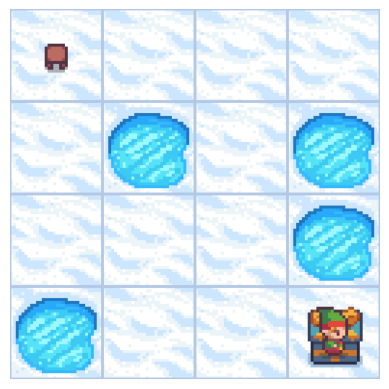

In [45]:
final_policy = np.zeros((num_states))

for state in range(num_states):
    for action in range(num_actions):
        final_policy = np.argmax(optimal_policy, axis=1)


print(final_policy)


state = env.reset()
done = False
t = 0
while not done:
    time.sleep(0.5)
    action = final_policy[state]
    next_state, reward, done, _ = env.step(action)
    t += 1
    state = next_state

    plt.axis('off')
    plt.imshow(env.render(mode='rgb_array'))
    display.display(plt.gcf())
    display.clear_output(wait=True)

env.close()

## 6. Value Iteration

### Your task: implement the value iteration algorithm.

Initialize $ V(s) $ to arbitrary values  
Repeat until $ V(s) $ converges  
&emsp;&emsp;For all states $ s $  
&emsp;&emsp;&emsp;&emsp;For all actions $ a $  
&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;$ Q(s, a) \leftarrow \sum_{s'} P(s' \mid s,a) \left( R(s, a, s') + \gamma V(s') \right)$

&emsp;&emsp;&emsp;&emsp;$ V(s) \leftarrow \max_a Q(s, a) $



In [46]:
# def value_iteration():
#     ##########################################
#     ##########################################
#     ############## To Implement ##############
#     ##########################################
#     ##########################################
#     pass

#     return policy

def value_iteration():
    V = np.zeros(num_states)
    while True:
        delta = 0.0
        for s in range(num_states):
            Q = np.zeros(num_actions)
            for a in range(num_actions):
                for prob, next_s, reward, done in env.P[s][a]:
                    Q[a] += prob * (reward + gamma * V[next_s])
            max_q = np.max(Q)
            delta = max(delta, abs(max_q - V[s]))
            V[s] = max_q
        if delta < theta:
            break

    # extract greedy policy
    policy = np.zeros((num_states, num_actions))
    for s in range(num_states):
        Q = np.zeros(num_actions)
        for a in range(num_actions):
            for prob, next_s, reward, done in env.P[s][a]:
                Q[a] += prob * (reward + gamma * V[next_s])
        best_a = np.argmax(Q)
        policy[s, best_a] = 1.0
    return policy

value_iteration_policy = value_iteration()
print("Value‐iteration policy (one‐hot):\n", value_iteration_policy)
print("Actions per state:", np.argmax(value_iteration_policy, axis=1))

Value‐iteration policy (one‐hot):
 [[0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]]
Actions per state: [1 2 1 0 1 0 1 0 2 1 1 0 0 2 2 0]


In [47]:
value_iteration_policy = value_iteration()

final_value_iteration_policy = np.zeros((num_states))
for state in range(num_states):
    for action in range(num_actions):
        final_value_iteration_policy = np.argmax(value_iteration_policy, axis=1)


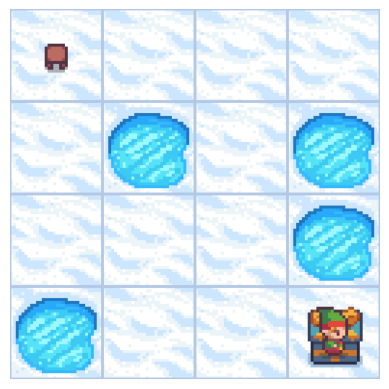

In [48]:
state = env.reset()
done = False
t = 0
while not done:
    time.sleep(0.5)
    action = final_value_iteration_policy[state]
    next_state, reward, done, _ = env.step(action)
    t += 1
    state = next_state

    plt.axis('off')
    plt.imshow(env.render(mode='rgb_array'))
    display.display(plt.gcf())
    display.clear_output(wait=True)

env.close()